# Multilingual Episodic Prototypical Contrastive Network (MEPC)

In [1]:
import json
import math
import os
import random
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import (
    AutoTokenizer,
    AutoModel,
)
EXECUTION_STARTED_AT = time.perf_counter()

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report, 
    confusion_matrix
)

## Reproducibility and configuration

Dataset paths, split policy, and hyperparameters are centralized below. Every corpus is read from `datasets/` with its six-class label already stored: GoEmotions keeps its official English split, while MYBully and CMED are split 70/15/15. MYBully supplies all Malay training, validation, and test samples; the auxiliary SupCon objective only contrasts the dataset pairs listed in `CONFIG['contrastive_pairings']`.

In [2]:
cwd = Path.cwd().resolve()
project_candidates = []
modal_root = Path(os.getenv('MODAL_PROJECT_ROOT', '/mnt/metalearning-contrastive')).expanduser()
if os.getenv('MODAL_NOTEBOOK', '').strip().lower() in {'1', 'true', 'yes'} and modal_root.is_dir():
    project_candidates.append(modal_root)
project_candidates.append(cwd)
project_candidates.extend(cwd.parents)
PROJECT_ROOT = next(
    (candidate for candidate in project_candidates if (candidate / 'datasets').is_dir()),
    cwd,
)

RUN_NAME = 'mepc'
DATA_DIR = PROJECT_ROOT / 'datasets'
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUTS_DIR = PROJECT_ROOT / 'outputs' / RUN_NAME
FIGURES_DIR = PROJECT_ROOT / 'figures' / RUN_NAME
DIRS = [MODELS_DIR, OUTPUTS_DIR, FIGURES_DIR]
for d in DIRS:
    d.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = MODELS_DIR / 'best_mepc.pt'
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f'{DATA_DIR} is missing; this notebook reads the local corpora from datasets/'
    )
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_DIR:', DATA_DIR)
print('checkpoint:', CHECKPOINT_PATH)

PROJECT_ROOT: /mnt/metalearning-contrastive
DATA_DIR: /mnt/metalearning-contrastive/datasets
checkpoint: /mnt/metalearning-contrastive/models/best_mepc.pt


In [3]:
SEED = 42
CANONICAL_LABELS = ['anger', 'disgust', 'joy', 'neutral', 'sadness', 'surprise']
LABEL_TO_ID = {x:i for i,x in enumerate(CANONICAL_LABELS)}

# Local files only: each one already carries the canonical six-class `label`.
DATA_CONFIG = {
    'goemotions': {
        'language': 'en',
        'separator': ',',
        'split_policy': 'official',
        'files': {
            'train': 'goemotions/train.csv',
            'validation': 'goemotions/validation.csv',
            'test': 'goemotions/test.csv',
        },
    },
    'mybully': {
        'language': 'ms',
        'separator': ',',
        'split_policy': '70-15-15',
        'files': {
            'train': 'mybully/train.csv',
            'validation': 'mybully/val.csv',
        },
    },
    'cmed': {
        'language': 'zh',
        'separator': ',',
        'split_policy': '70-15-15',
        'files': {
            'train': 'cmed/train.csv',
        },
    },
}

MALAY_DATASETS = ['mybully']
DATASET_TO_ID = {name: index for index, name in enumerate(DATA_CONFIG)}

CONFIG = {
    'model_name': 'xlm-roberta-base',
    'architecture': 'Multilingual Episodic Prototypical Contrastive Network (MEPC)',
    'encoder_candidates': [
        'xlm-roberta-base',
        'sentence-transformers/paraphrase-multilingual-mpnet-base-v2',
    ],
    'max_length': 140,
    'projection_dim': 256,
    'dropout': .25,
    'ways': 6,
    'shots': 10,
    'queries_per_class': 16,
    'max_shots': 15,
    'query_domain_weights': {'ms': .80, 'en': .10, 'zh': .10},
    'temperature': .18,
    'encoder_learning_rate': 2e-5,
    'projection_learning_rate': 5e-4,
    'encoder_layerwise_lr_decay': .90,
    'weight_decay': .01,
    'epochs': 15,
    'minimum_epochs': 10,
    'episodes_per_epoch': 500,
    'gradient_accumulation_steps': 4,
    'encoding_micro_batch_size': 16,
    # No linear warmup any more: epoch 1 holds the initial learning rates instead,
    # so this share is kept only for reference by older runs.
    'warmup_ratio': .10,
    'maximum_gradient_norm': 1.,
    'early_stopping_patience': 4,
    'checkpoint_selection': {'balanced_accuracy': .5, 'macro_f1': .5},
    'episode_mix': {
        'monolingual': .40, 'cross_lingual': .40, 'mixed_support': .20
    },
    'gradient_checkpointing': True,
    'loss_type': 'cross_entropy',
    'focal_gamma': 2.,
    'focal_alpha_mode': 'inverse_frequency',
    'focal_alpha': None,
    'focal_alpha_range': (.3, 3.),
    'effective_number_beta': .9999,
    'allow_oversampling_with_focal_alpha': False,
    # Prototype shrinkage only fires for classes with at most this many support
    # examples, so the threshold must stay <= CONFIG['shots'] // 2 to be reachable;
    # at 5 with shots=10 it sits exactly on that boundary.
    'prototype_shrinkage_max_count': 5,
    'prototype_shrinkage_prior': 1.,
    'prototype_count': 2,
    'single_prototype_fallback': True,
    'transductive_rounds': 0,
    'freeze_encoder_epochs': 0,
    'supcon_initial_weight': .08,
    'supcon_temperature': .18,
    'supcon_decay': 'linear',
    'W_WITHIN': 1.0,
    'W_CROSS_DATASET': .75,
    'W_CROSS_LANGUAGE': .50,
    'calibration_enabled': True,
    'calibration_regularization': .01,
    'calibration_learning_rate': .25,
    'calibration_steps': 6,
    'calibration_grid_size': 9,
}


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=False)

def dataloader_worker_init_fn(worker_id):
    seed_everything(SEED + worker_id)

DATALOADER_GENERATOR = torch.Generator().manual_seed(SEED)
seed_everything()

print('seed =', SEED, '; DataLoader workers use dataloader_worker_init_fn; deterministic PyTorch algorithms are required. CUDA results can still vary across hardware and library versions.')
print('datasets:', {name: spec['language'] for name, spec in DATA_CONFIG.items()})
print('Malay dataset: MYBully | SupCon pair weights:',
      {name: CONFIG[name] for name in ('W_WITHIN', 'W_CROSS_DATASET', 'W_CROSS_LANGUAGE')})

seed = 42 ; DataLoader workers use dataloader_worker_init_fn; deterministic PyTorch algorithms are required. CUDA results can still vary across hardware and library versions.
datasets: {'goemotions': 'en', 'mybully': 'ms', 'cmed': 'zh'}
Malay dataset: MYBully | SupCon pair weights: {'W_WITHIN': 1.0, 'W_CROSS_DATASET': 0.75, 'W_CROSS_LANGUAGE': 0.5}


## Hardware
Episodes never span devices. A notebook safely uses one CUDA device; when multiple GPUs are detected, use an externally launched one-process-per-GPU PyTorch `DistributedDataParallel` (DDP) job for real distributed training. This notebook does not use model parallelism or implicitly initialize DDP in the kernel.

In [4]:
cuda = torch.cuda.is_available()
device = torch.device('cuda:0' if cuda else 'cpu')

print('CUDA available:', cuda, '| count:', torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(i, p.name, f'{p.total_memory/2**30:.2f} GiB')

bf16 = cuda and torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if bf16 else torch.float16
AMP = cuda

print('device:', device, 'mixed precision:', AMP_DTYPE if AMP else 'off')
if torch.cuda.device_count() > 1:
    print('Safe notebook fallback: cuda:0. For DDP, launch equivalent code with torchrun; do not use DataParallel/model parallelism.')

CUDA available: True | count: 1
0 NVIDIA A10 22.06 GiB
device: cuda:0 mixed precision: torch.bfloat16


## Load the local datasets

Each file already stores the canonical six-class `label`. Rows the labeling policy could not place were written with `label_status != 'kept'` and are filtered out here, so this notebook never remaps a label string.

In [5]:
def read_local_frame(name, filename):
    spec = DATA_CONFIG[name]
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {name} file: {path}.'
        )
    frame = pd.read_csv(path, sep=spec['separator'], dtype=str, keep_default_na=False)
    missing = {'sample_id', 'text', 'label'} - set(frame.columns)
    if missing:
        raise ValueError(f'{path}: missing columns {sorted(missing)}; found {list(frame.columns)}')
    if 'label_status' in frame.columns:
        frame = frame[frame.label_status == 'kept'].copy()
    frame = frame[frame.label.isin(CANONICAL_LABELS)].copy()
    if frame.empty:
        raise ValueError(f'{path}: no labeled rows after filtering')
    if not frame.text.str.strip().all():
        raise ValueError(f'{path}: contains empty text')
    if not frame.sample_id.is_unique:
        raise ValueError(f'{path}: duplicate sample_id')
    # Preserve provenance so translated/source-linked rows never become positives.
    source_column = next((column for column in ('source_id', 'source_example_id', 'goemotions_id')
                          if column in frame.columns), None)
    frame['source_link_id'] = frame[source_column].astype(str) if source_column else ''
    frame['dataset'] = name
    frame['language'] = spec['language']
    return frame[['sample_id', 'dataset', 'language', 'source_link_id', 'text', 'label']].reset_index(drop=True)


LOCAL = {
    name: {split: read_local_frame(name, filename) for split, filename in spec['files'].items()}
    for name, spec in DATA_CONFIG.items()
}

for name, frames in LOCAL.items():
    joined = pd.concat(frames.values(), ignore_index=True)
    counts = joined.label.value_counts().reindex(CANONICAL_LABELS).fillna(0).astype(int)
    if (counts == 0).any():
        raise ValueError(f'{name} lacks classes: {counts[counts == 0].index.tolist()}')
    print(f'{name} ({DATA_CONFIG[name]["language"]}): ' + ', '.join(
        f'{split}={len(frame):,}' for split, frame in frames.items()
    ))
    print('   ', counts.to_dict())

goemotions (en): train=39,014, validation=4,874, test=4,888
    {'anger': 5420, 'disgust': 635, 'joy': 19020, 'neutral': 16021, 'sadness': 2875, 'surprise': 4805}
mybully (ms): train=3,449, validation=1,152
    {'anger': 2450, 'disgust': 393, 'joy': 437, 'neutral': 971, 'sadness': 276, 'surprise': 74}
cmed (zh): train=4,159
    {'anger': 527, 'disgust': 404, 'joy': 1152, 'neutral': 705, 'sadness': 486, 'surprise': 885}


## Fixed outer splits

GoEmotions keeps its official train/dev/test files. MYBully and CMED are split 70/15/15 with stratification. Duplicate IDs are prevented from crossing any split.

In [6]:
def stratified_70_15_15(frame):
    frame = frame.drop_duplicates('sample_id').reset_index(drop=True)
    counts = frame.label.value_counts()
    if (counts < 3).any():
        raise ValueError(f'Need >=3/class after mapping: {counts.to_dict()}')
    train, holdout = train_test_split(
        frame,
        test_size=0.30,
        stratify=frame.label,
        random_state=SEED,
    )
    validation, test = train_test_split(
        holdout,
        test_size=0.50,
        stratify=holdout.label,
        random_state=SEED,
    )
    return {
        'train': train.reset_index(drop=True),
        'validation': validation.reset_index(drop=True),
        'test': test.reset_index(drop=True),
    }


def resolve_splits(name):
    spec = DATA_CONFIG[name]
    frames = {split: frame.copy() for split, frame in LOCAL[name].items()}
    if spec['split_policy'] == '70-15-15':
        if 'test' in frames:
            raise ValueError(f'{name}: the 70/15/15 policy would discard the stored test split')
        return stratified_70_15_15(pd.concat(frames.values(), ignore_index=True))
    if spec['split_policy'] == 'official':
        if 'test' not in frames or 'validation' not in frames:
            raise ValueError(f'{name}: the official policy needs stored validation and test splits')
        return frames
    raise ValueError(f'{name}: unknown split_policy {spec["split_policy"]!r}')


SPLITS_BY_DATASET = {name: resolve_splits(name) for name in DATA_CONFIG}
splits = {
    split: pd.concat(
        [SPLITS_BY_DATASET[name][split] for name in DATA_CONFIG],
        ignore_index=True,
    )
    for split in ('train', 'validation', 'test')
}

for split_name, frame in splits.items():
    assert frame.sample_id.is_unique
    assert frame.label.isin(CANONICAL_LABELS).all()
    assert frame.label.notna().all()
    print(f'\n{split_name}: n={len(frame)}')
    print(frame.groupby(['dataset', 'label']).size().unstack(fill_value=0))

split_ids = [set(splits[name].sample_id) for name in ('train', 'validation', 'test')]
assert not (split_ids[0] & split_ids[1] or split_ids[0] & split_ids[2] or split_ids[1] & split_ids[2])
print('No leakage across the three outer splits.')


malay = {
    'train': SPLITS_BY_DATASET['mybully']['train'],
    'validation': SPLITS_BY_DATASET['mybully']['validation'],
    'test': SPLITS_BY_DATASET['mybully']['test'],
}

for split_name in ('validation', 'test'):
    frame = malay[split_name]
    share = frame.dataset.value_counts(normalize=True).round(3).to_dict()
    print(f'\nMYBully {split_name}: n={len(frame)} | dataset share {share}')
    print(frame.groupby(['dataset', 'label']).size().unstack(fill_value=0))
    assert set(frame.label) == set(CANONICAL_LABELS)

malay_ids = {split: set(frame.sample_id) for split, frame in malay.items()}
assert not (malay_ids['train'] & malay_ids['validation'])
assert not (malay_ids['train'] & malay_ids['test'])
assert not (malay_ids['validation'] & malay_ids['test'])
assert malay['train'].sample_id.is_unique
assert set(malay['train'].dataset) == set(MALAY_DATASETS)
print('\nMYBully train/validation/test frames are disjoint.')


train: n=45145
label       anger  disgust    joy  neutral  sadness  surprise
dataset                                                      
cmed          369      283    806      494      340       619
goemotions   4293      498  15216    12823     2326      3858
mybully      1715      275    306      679      193        52

validation: n=6188
label       anger  disgust   joy  neutral  sadness  surprise
dataset                                                     
cmed           79       60   173      106       73       133
goemotions    555       61  1941     1592      266       459
mybully       367       59    65      146       42        11

test: n=6203
label       anger  disgust   joy  neutral  sadness  surprise
dataset                                                     
cmed           79       61   173      105       73       133
goemotions    572       76  1863     1606      283       488
mybully       368       59    66      146       41        11
No leakage across the three ou

## Deterministic balanced episodic sampling

Support and query IDs are disjoint. All Malay training and evaluation samples come from MYBully. SupCon positives are same-label rows from the same language or from an explicitly paired dataset. Mixed support still uses a per-class language choice with primarily Malay queries.


In [7]:
def pool(frame, language, label):
    return frame[(frame.language == language) & (frame.label == label)]


def sampling_weights(subset):
    if subset.dataset.nunique() <= 1:
        return None
    raise ValueError('Multiple Malay datasets are not configured')


def draw(frame, language, label, count, rng):
    subset = pool(frame, language, label)
    if count > len(subset):
        raise ValueError(f'Cannot draw {count} {label!r}/{language} rows from a pool of {len(subset)}')
    positions = rng.choice(len(subset), count, replace=False, p=sampling_weights(subset))
    return subset.iloc[positions]


def shot_counts(frame):
    counts = frame.label.value_counts()
    reference = counts.median()
    return {
        label: min(
            CONFIG['max_shots'],
            max(CONFIG['shots'], math.ceil(CONFIG['shots'] * reference / counts[label])),
            min(
                len(pool(frame, language, label)) - CONFIG['queries_per_class']
                for language in frame.language.unique()
            ),
        )
        for label in CANONICAL_LABELS
    }


def shot_counts_by_dataset(frame):
    # Shot budget each corpus would get on its own, used to cap its weighted share.
    return {
        dataset: shot_counts(frame[frame.dataset == dataset])
        for dataset in sorted(frame.dataset.unique())
    }


def malay_draw_parts(frame, label, support_count, query_count, rng):
    subset = frame[frame.dataset == 'mybully']
    selected = draw(subset, 'ms', label, support_count + query_count, rng)
    return selected.iloc[:support_count], selected.iloc[support_count:]


def feasible(frame, shots):
    return [
        language
        for language in sorted(frame.language.unique())
        if all(
            len(pool(frame, language, label)) >= shots[label] + CONFIG['queries_per_class']
            for label in CANONICAL_LABELS
        )
    ]


MALAY_SHOT_BUDGETS = shot_counts_by_dataset(malay['train'])


def sample_episode(frame, epoch, index, seed=SEED):
    rng = np.random.default_rng(seed + 1_000_003 * epoch + index)
    shots = shot_counts(frame)
    languages = feasible(frame, shots)
    if not languages:
        raise RuntimeError(
            'No language has enough examples/class for the configured shot schedule.'
        )

    episode_type = rng.choice(
        ['monolingual', 'cross_lingual', 'mixed_support'],
        p=list(CONFIG['episode_mix'].values()),
    )
    query_weights = np.array([CONFIG['query_domain_weights'].get(language, 0) for language in languages], dtype=float)
    query_weights /= query_weights.sum()
    query_language = rng.choice(languages, p=query_weights)
    foreign_languages = [language for language in languages if language != query_language]
    if episode_type == 'monolingual':
        support_languages = [query_language] * CONFIG['ways']
        query_languages = support_languages
    elif episode_type == 'cross_lingual' and foreign_languages:
        support_languages = [rng.choice(foreign_languages)] * CONFIG['ways']
        query_languages = [query_language] * CONFIG['ways']
    elif episode_type == 'mixed_support' and len(languages) > 1:
        support_languages = [rng.choice(languages) for _ in CANONICAL_LABELS]
        query_languages = [query_language] * CONFIG['ways']
    else:
        support_languages = [query_language] * CONFIG['ways']
        query_languages = support_languages

    support_parts = []
    query_parts = []
    for label, support_language, query_language in zip(
        CANONICAL_LABELS,
        support_languages,
        query_languages,
    ):
        if support_language == query_language:
            if support_language == 'ms':
                part_support, part_query = malay_draw_parts(
                    frame, label, shots[label], CONFIG['queries_per_class'], rng,
                )
            else:
                selected = draw(
                    frame,
                    support_language,
                    label,
                    shots[label] + CONFIG['queries_per_class'],
                    rng,
                )
                part_support = selected.iloc[:shots[label]]
                part_query = selected.iloc[shots[label]:]
        else:
            if support_language == 'ms':
                part_support, _ = malay_draw_parts(frame, label, shots[label], 0, rng)
            else:
                part_support = draw(frame, support_language, label, shots[label], rng)
            if query_language == 'ms':
                _, part_query = malay_draw_parts(frame, label, 0, CONFIG['queries_per_class'], rng)
            else:
                part_query = draw(frame, query_language, label, CONFIG['queries_per_class'], rng)
        if part_support is None or part_query is None:
            raise RuntimeError(f'Empty {label!r} draw for {support_language}/{query_language}')
        support_parts.append(part_support)
        query_parts.append(part_query)

    support = pd.concat(support_parts, ignore_index=True)
    query = pd.concat(query_parts, ignore_index=True)
    assert not (set(support.sample_id) & set(query.sample_id))
    support = support.sample(frac=1, random_state=seed + index).reset_index(drop=True)
    query = query.sample(frac=1, random_state=seed + index + 99).reset_index(drop=True)
    return support, query, episode_type


support, query, episode_type = sample_episode(splits['train'], 0, 0)
support_again, query_again, _ = sample_episode(splits['train'], 0, 0)

print('Episode reproducibility and support/query disjointness passed.')
print('Scheduled shots per label:', shot_counts(splits['train']))
print('MYBully shot budgets:', MALAY_SHOT_BUDGETS)

malay_pool_probe = pool(splits['train'], 'ms', 'anger')

probe_rng = np.random.default_rng(SEED)
probe_positions = probe_rng.choice(len(malay_pool_probe), 600, replace=False, p=sampling_weights(malay_pool_probe))
assert (malay_pool_probe.iloc[probe_positions].dataset == 'mybully').all()

print('MYBully draw composition check passed.')


Episode reproducibility and support/query disjointness passed.
Scheduled shots per label: {'anger': 10, 'disgust': 15, 'joy': 10, 'neutral': 10, 'sadness': 15, 'surprise': 13}
MYBully shot budgets: {'mybully': {'anger': 10, 'disgust': 11, 'joy': 10, 'neutral': 10, 'sadness': 15, 'surprise': 15}}
MYBully draw composition check passed.


## Multilingual encoder, prototypes, focal loss, and weighted supervised contrastive learning

Mean pooling is attention-mask aware. The model uses the requested multilingual sentence-transformer encoder without a classification head. `build_prototypes` L2-normalizes each class prototype and shrinks only classes with 1-2 support examples toward the global support mean. Focal alpha is computed from training counts and clipped to the configured range.

The auxiliary weighted SupCon term uses metadata: same-label pairs are weighted as within-dataset/same-language, cross-dataset/same-language, or cross-language. The anchor is excluded, translated/source-linked examples are excluded, and each valid anchor normalizes by its total positive weight.


In [8]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG['model_name'])


class ProtoNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(CONFIG['model_name'])
        self.drop = nn.Dropout(CONFIG['dropout'])
        self.projection = nn.Linear(self.encoder.config.hidden_size, CONFIG['projection_dim'])
        self.norm = nn.LayerNorm(CONFIG['projection_dim'])
        if CONFIG['gradient_checkpointing']:
            self.encoder.gradient_checkpointing_enable()

    def forward(self, input_ids, attention_mask):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp_min(1e-9)
        return self.norm(self.projection(self.drop(pooled)))


def raw_alpha_from_train(frame):
    # Unclipped, mean-normalised alpha; kept separate so the clipping can be inspected.
    if CONFIG['focal_alpha'] is not None:
        alpha = np.asarray(CONFIG['focal_alpha'], dtype=float)
        if alpha.shape != (CONFIG['ways'],):
            raise ValueError('focal_alpha must have one value per class')
        return alpha
    mode = CONFIG['focal_alpha_mode']
    if mode == 'none':
        return None
    counts = np.array([(frame.label == label).sum() for label in CANONICAL_LABELS], dtype=float)
    if (counts == 0).any():
        raise ValueError('automatic alpha needs every training class')
    if mode == 'inverse_frequency':
        alpha = 1 / counts
    elif mode == 'effective_number':
        beta = CONFIG['effective_number_beta']
        alpha = (1 - beta) / (1 - np.power(beta, counts))
    else:
        raise ValueError('invalid focal_alpha_mode')
    return alpha / alpha.mean()


def alpha_from_train(frame):
    low, high = CONFIG['focal_alpha_range']
    raw = raw_alpha_from_train(frame)
    if raw is None:
        return None
    return torch.tensor(np.clip(raw, low, high), dtype=torch.float32)


FOCAL_ALPHA = alpha_from_train(splits['train'])
RAW_FOCAL_ALPHA = raw_alpha_from_train(splits['train'])
if FOCAL_ALPHA is not None:
    print('Focal alpha raw (pre-clip):', [round(float(value), 4) for value in RAW_FOCAL_ALPHA])
    print('Focal alpha (clipped):    ', [round(float(value), 4) for value in FOCAL_ALPHA])
    # The widened range is only meaningful if the raw values actually hit it.
    assert np.any((RAW_FOCAL_ALPHA < 0.7) | (RAW_FOCAL_ALPHA > 1.3)), (
        'every raw focal alpha already lies inside [0.7, 1.3]; the clip is a no-op'
    )


def loss_fn(logits, target):
    cross_entropy = F.cross_entropy(logits, target, reduction='none')
    if CONFIG['loss_type'] == 'cross_entropy':
        return cross_entropy.mean()
    if CONFIG['loss_type'] != 'focal':
        raise ValueError('loss_type must be cross_entropy or focal')
    alpha = torch.ones(CONFIG['ways'], device=logits.device, dtype=logits.dtype)
    if FOCAL_ALPHA is not None:
        alpha = FOCAL_ALPHA.to(logits.device, logits.dtype)
    loss = alpha[target] * (1 - torch.exp(-cross_entropy)).pow(CONFIG['focal_gamma']) * cross_entropy
    loss = loss.mean()
    if not torch.isfinite(loss):
        raise FloatingPointError('nonfinite focal loss')
    return loss


def encode(model, texts, grad=False):
    embeddings = []
    context = torch.enable_grad() if grad else torch.no_grad()
    with context:
        for start in range(0, len(texts), CONFIG['encoding_micro_batch_size']):
            batch_texts = list(texts[start:start + CONFIG['encoding_micro_batch_size']])
            batch = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=CONFIG['max_length'],
                return_tensors='pt',
            ).to(device)
            embeddings.append(model(**batch))
    return torch.cat(embeddings)


def _single_prototype(class_embeddings, global_mean):
    class_mean = class_embeddings.mean(0)
    class_count = class_embeddings.shape[0]
    if class_count <= CONFIG['prototype_shrinkage_max_count']:
        shrinkage = class_count / (class_count + CONFIG['prototype_shrinkage_prior'])
        class_mean = shrinkage * class_mean + (1 - shrinkage) * global_mean
    return F.normalize(class_mean, p=2, dim=0)


def _multi_prototypes(class_embeddings, global_mean):
    count = class_embeddings.shape[0]
    if CONFIG['prototype_count'] < 2 or count < 2:
        if not CONFIG['single_prototype_fallback']:
            raise ValueError('Two prototypes require at least two support examples per class')
        prototype = _single_prototype(class_embeddings, global_mean)
        return prototype.repeat(CONFIG['prototype_count'], 1)

    # Deterministic two-means assignment keeps both prototypes tied to support embeddings.
    points = F.normalize(class_embeddings, p=2, dim=1)
    first = points.mean(0)
    second = points[(points - first).pow(2).sum(1).argmax()]
    centers = torch.stack([first, second])
    for _ in range(8):
        assignment = ((points[:, None, :] - centers[None, :, :]).pow(2).sum(-1)).argmin(1)
        if (assignment == 0).sum() == 0 or (assignment == 1).sum() == 0:
            if not CONFIG['single_prototype_fallback']:
                raise ValueError('Prototype assignment produced an empty cluster')
            prototype = _single_prototype(class_embeddings, global_mean)
            return prototype.repeat(CONFIG['prototype_count'], 1)
        updated = torch.stack([points[assignment == index].mean(0) for index in range(2)])
        if torch.allclose(updated, centers, atol=1e-5, rtol=1e-4):
            centers = updated
            break
        centers = updated
    return F.normalize(centers, p=2, dim=1)


def build_prototypes(support_embeddings, support_labels):
    global_mean = support_embeddings.mean(0)
    prototypes = []
    for index in range(CONFIG['ways']):
        class_embeddings = support_embeddings[support_labels == index]
        if class_embeddings.shape[0] == 0:
            raise ValueError(f'No support examples for class index {index}')
        prototypes.append(_multi_prototypes(class_embeddings, global_mean))
    prototypes = torch.stack(prototypes)
    assert prototypes.shape == (
        CONFIG['ways'], CONFIG['prototype_count'], support_embeddings.shape[-1]
    )
    return prototypes


def cosine_logits(query_embeddings, prototypes):
    if prototypes.ndim == 2:
        prototypes = prototypes[:, None, :]
    similarities = F.cosine_similarity(
        query_embeddings[:, None, None, :], prototypes[None, :, :, :], dim=-1,
    )
    # Averaging in probability space makes duplicate fallback prototypes neutral.
    logits = torch.logsumexp(similarities / CONFIG['temperature'], dim=2)
    logits = logits - math.log(prototypes.shape[2])
    assert logits.shape == (len(query_embeddings), CONFIG['ways'])
    return logits


def logits_from_episode(support_embeddings, support_labels, query_embeddings):
    return cosine_logits(query_embeddings, build_prototypes(support_embeddings, support_labels))


def metrics(losses, targets, predictions):
    return {
        'loss': float(np.mean(losses)),
        'accuracy': accuracy_score(targets, predictions),
        'balanced_accuracy': balanced_accuracy_score(targets, predictions),
        'macro_f1': f1_score(targets, predictions, average='macro', zero_division=0),
        'weighted_f1': f1_score(targets, predictions, average='weighted', zero_division=0),
    }


probe = torch.randn(4, CONFIG['ways'], requires_grad=True)
probe_loss = loss_fn(probe, torch.tensor([0, 1, 2, 3]))


DATASET_LANGUAGE_IDS = torch.tensor([
    {'en': 0, 'ms': 1, 'zh': 2}[DATA_CONFIG[name]['language']]
    for name in DATA_CONFIG
], dtype=torch.long)


def source_link_tensor(source_links, device):
    # Empty provenance is deliberately unique, so only known source links match.
    link_to_id, ids = {}, []
    for index, source_link in enumerate(source_links):
        if source_link:
            ids.append(link_to_id.setdefault(source_link, len(link_to_id)))
        else:
            ids.append(-index - 1)
    return torch.tensor(ids, dtype=torch.long, device=device)


def supcon_pair_weights(labels, datasets, source_links=None):
    if labels.ndim != 1 or datasets.ndim != 1 or len(labels) != len(datasets):
        raise ValueError('SupCon labels and datasets must be one-dimensional and aligned')
    if source_links is None:
        source_links = torch.full_like(labels, -1)
    if source_links.ndim != 1 or len(source_links) != len(labels):
        raise ValueError('SupCon source links must be one-dimensional and aligned')

    # Categories are determined solely from dataset/language/provenance metadata.
    n = len(labels)
    self_mask = torch.eye(n, dtype=torch.bool, device=labels.device)
    same_label = labels[:, None] == labels[None, :]
    same_dataset = datasets[:, None] == datasets[None, :]
    language_ids = DATASET_LANGUAGE_IDS.to(labels.device)[datasets]
    same_language = language_ids[:, None] == language_ids[None, :]
    same_source = ((source_links[:, None] == source_links[None, :])
                   & (source_links[:, None] >= 0) & (source_links[None, :] >= 0))
    eligible = same_label & ~self_mask & ~same_source
    categories = {
        'within_dataset': eligible & same_dataset,
        'cross_dataset': eligible & ~same_dataset & same_language,
        'cross_language': eligible & ~same_language,
    }
    weights = torch.zeros((n, n), dtype=torch.float32, device=labels.device)
    weights = weights.masked_fill(categories['within_dataset'], CONFIG['W_WITHIN'])
    weights = weights.masked_fill(categories['cross_dataset'], CONFIG['W_CROSS_DATASET'])
    weights = weights.masked_fill(categories['cross_language'], CONFIG['W_CROSS_LANGUAGE'])
    return weights, categories


def supcon_loss(embeddings, labels, datasets, source_links=None, temperature=0.1, return_stats=False):
    if temperature <= 0:
        raise ValueError('SupCon temperature must be positive')
    z = F.normalize(embeddings, dim=-1)
    similarity = (z @ z.T) / temperature
    n = z.size(0)
    self_mask = torch.eye(n, dtype=torch.bool, device=z.device)
    pair_weights, categories = supcon_pair_weights(labels, datasets, source_links)
    similarity = similarity.masked_fill(self_mask, -float('inf'))
    positive_weight = pair_weights.sum(1)
    valid = positive_weight > 0
    stats = {
        'valid_anchors': valid.sum(),
        **{f'valid_anchors_{name}': (mask.any(dim=1) & valid).sum()
           for name, mask in categories.items()},
        **{f'pairs_{name}': mask.sum() for name, mask in categories.items()},
    }
    if not valid.any():
        loss = embeddings.sum() * 0.0
    else:
        valid_similarity = similarity[valid]
        valid_weights = pair_weights[valid].to(valid_similarity.dtype)
        log_probability = valid_similarity - torch.logsumexp(valid_similarity, dim=1, keepdim=True)
        # Avoid 0 * -inf for the diagonal and ineligible pairs.
        log_probability = torch.where(valid_weights > 0, log_probability, torch.zeros_like(log_probability))
        # Conventional weighted SupCon: average each eligible positive pair's log-probability
        # with its normalized category weight, then average the valid anchors.
        row_loss = -(valid_weights * log_probability).sum(1) / positive_weight[valid].to(valid_similarity.dtype)
        loss = row_loss.mean()
    if not torch.isfinite(loss):
        raise FloatingPointError('nonfinite weighted SupCon loss')
    return (loss, stats) if return_stats else loss


# Sanity checks cover cross-dataset weighting, provenance exclusion, and gradients.
supcon_probe_labels = torch.arange(CONFIG['ways'], device=device).repeat_interleave(2)
supcon_probe_datasets = torch.tensor(
    [DATASET_TO_ID['mybully']] * (2 * CONFIG['ways']),
    device=device,
)
supcon_probe_embeddings = torch.randn(
    len(supcon_probe_labels), CONFIG['projection_dim'], device=device, requires_grad=True
)
supcon_probe_links = source_link_tensor([''] * len(supcon_probe_labels), device)
supcon_probe_loss = supcon_loss(
    supcon_probe_embeddings,
    supcon_probe_labels,
    supcon_probe_datasets,
    supcon_probe_links,
    temperature=CONFIG['supcon_temperature'],
)

same_dataset_loss = supcon_loss(
    supcon_probe_embeddings.detach(),
    supcon_probe_labels,
    torch.full_like(supcon_probe_datasets, DATASET_TO_ID['mybully']),
    temperature=CONFIG['supcon_temperature'],
)
assert torch.isfinite(same_dataset_loss) and same_dataset_loss.item() > 0
linked_loss = supcon_loss(
    supcon_probe_embeddings.detach(),
    supcon_probe_labels,
    supcon_probe_datasets,
    source_link_tensor(['same'] * len(supcon_probe_labels), device),
    temperature=CONFIG['supcon_temperature'],
)
assert linked_loss.item() == 0
no_pairs_loss = supcon_loss(
    supcon_probe_embeddings.detach(),
    torch.arange(len(supcon_probe_labels), device=device),
    supcon_probe_datasets,
    temperature=CONFIG['supcon_temperature'],
)
assert no_pairs_loss.item() == 0 and torch.isfinite(no_pairs_loss)
prototype_probe_embeddings = torch.randn(
    CONFIG['ways'] * 2, CONFIG['projection_dim'], device=device, requires_grad=True,
)
prototype_probe_labels = torch.arange(CONFIG['ways'], device=device).repeat_interleave(2)
prototype_probe = build_prototypes(prototype_probe_embeddings, prototype_probe_labels)
assert prototype_probe.shape == (
    CONFIG['ways'], CONFIG['prototype_count'], CONFIG['projection_dim']
)
assert torch.isfinite(prototype_probe).all()
print('Weighted SupCon and multi-prototype sanity checks passed:', float(supcon_probe_loss))


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Focal alpha raw (pre-clip): [0.5207, 3.1443, 0.2034, 0.2372, 1.1614, 0.7331]
Focal alpha (clipped):     [0.5207, 3.0, 0.3, 0.3, 1.1614, 0.7331]


Weighted SupCon and multi-prototype sanity checks passed: 2.3190486431121826


/tmp/ipykernel_5/1545190465.py:309: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print('Weighted SupCon and multi-prototype sanity checks passed:', float(supcon_probe_loss))


## Train and validate

MYBully validation samples are never supports: validation uses five fixed MYBully training support draws (`support_sets(5)`) and MYBully validation queries. Metrics are the mean over the five draws and are reported with a standard deviation. Checkpoints are selected on `0.5*balanced_accuracy + 0.5*macro_f1` of those means after at least 10 epochs; early stopping uses patience 4, and `ReduceLROnPlateau` halves each learning rate when the selection score stalls for two epochs (from epoch 2 on, so epoch 1 keeps the initial learning rates).

In [9]:
model = ProtoNet().to(device)


def build_optimizer():
    encoder_groups = []
    encoder = model.encoder
    layer_count = len(encoder.encoder.layer)
    decay = CONFIG['encoder_layerwise_lr_decay']
    encoder_groups.append({
        'params': encoder.embeddings.parameters(),
        'lr': CONFIG['encoder_learning_rate'] * decay ** layer_count,
        'group_name': 'encoder_embeddings',
    })
    for layer_index, layer in enumerate(encoder.encoder.layer):
        depth = layer_count - 1 - layer_index
        encoder_groups.append({
            'params': layer.parameters(),
            'lr': CONFIG['encoder_learning_rate'] * decay ** depth,
            'group_name': f'encoder_layer_{layer_index}',
        })
    other_encoder = [parameter for name, parameter in encoder.named_parameters()
                     if not (name.startswith('embeddings.') or name.startswith('encoder.layer.'))]
    if other_encoder:
        encoder_groups.append({
            'params': other_encoder,
            'lr': CONFIG['encoder_learning_rate'],
            'group_name': 'encoder_other',
        })
    encoder_groups.append({
        'params': list(model.projection.parameters()) + list(model.norm.parameters()),
        'lr': CONFIG['projection_learning_rate'],
        'group_name': 'projection_head',
    })
    return torch.optim.AdamW(encoder_groups, weight_decay=CONFIG['weight_decay'])


def encoder_learning_rate(optimizer):
    return max(group['lr'] for group in optimizer.param_groups
               if group['group_name'].startswith('encoder_'))


def head_learning_rate(optimizer):
    return next(group['lr'] for group in optimizer.param_groups
                if group['group_name'] == 'projection_head')


def set_encoder_trainable(trainable):
    for parameter in model.encoder.parameters():
        parameter.requires_grad = trainable
    if CONFIG['gradient_checkpointing']:
        if trainable:
            model.encoder.gradient_checkpointing_enable()
        else:
            model.encoder.gradient_checkpointing_disable()


def build_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)


if CONFIG['freeze_encoder_epochs'] > 0:
    set_encoder_trainable(False)
optimizer = build_optimizer()
assert all(group['lr'] > 0 for group in optimizer.param_groups)
assert head_learning_rate(optimizer) == CONFIG['projection_learning_rate']
scheduler = build_scheduler(optimizer)
scaler = torch.amp.GradScaler('cuda', enabled=AMP and AMP_DTYPE == torch.float16)
CLASS_LOGIT_BIASES = torch.zeros(CONFIG['ways'], device=device)


def support_sets(k=5):
    # k deterministic Malay support draws; draw i uses rng = default_rng(SEED + i).
    shots = shot_counts(malay['train'])
    frames = []
    for index in range(k):
        rng = np.random.default_rng(SEED + index)
        parts = [
            malay_draw_parts(malay['train'], label, shots[label], 0, rng)[0]
            for label in CANONICAL_LABELS
        ]
        if any(part is None for part in parts):
            raise RuntimeError('Empty Malay support draw')
        frame = pd.concat(parts, ignore_index=True)
        frames.append(frame.sample(frac=1, random_state=SEED + index).reset_index(drop=True))
    return frames


def refine_and_predict(query_embeddings, support_embeddings, support_labels, rounds=None, temperature=CONFIG['temperature']):
    if rounds is None:
        rounds = CONFIG['transductive_rounds']
    prototypes = build_prototypes(support_embeddings, support_labels)
    for _ in range(rounds):
        weights = F.softmax(cosine_logits(query_embeddings, prototypes) / 2.0, dim=1)
        augmented = []
        for class_index in range(CONFIG['ways']):
            support_mean = support_embeddings[support_labels == class_index].mean(0)
            query_weight = weights[:, class_index].sum().clamp_min(1e-6)
            query_mean = (query_embeddings * weights[:, class_index:class_index + 1]).sum(0) / query_weight
            augmented.append(F.normalize(support_mean + query_mean, p=2, dim=0))
        prototypes = torch.stack(augmented)[:, None, :].repeat(1, CONFIG['prototype_count'], 1)
    return cosine_logits(query_embeddings, prototypes)


def apply_class_calibration(logits, biases=None):
    if biases is None:
        biases = CLASS_LOGIT_BIASES
    return logits + biases.to(logits.device, logits.dtype)


def predict_logits(frame, num_supports=5, per_draw=False, refine_prototypes=True, rounds=None, apply_bias=True):
    model.eval()
    supports = support_sets(num_supports)
    with torch.no_grad():
        query_embeddings = encode(model, frame.text.tolist())
        logits_draws = []
        for support in supports:
            support_labels = torch.tensor(support.label.map(LABEL_TO_ID).values, device=device)
            support_embeddings = encode(model, support.text.tolist())
            if refine_prototypes:
                logits = refine_and_predict(query_embeddings, support_embeddings, support_labels, rounds=rounds)
            else:
                logits = cosine_logits(query_embeddings, build_prototypes(support_embeddings, support_labels))
            logits_draws.append(apply_class_calibration(logits) if apply_bias else logits)
        stacked_logits = torch.stack(logits_draws, dim=0)
        target = torch.tensor(frame.label.map(LABEL_TO_ID).values, device=device)
    if per_draw:
        return stacked_logits, target
    return stacked_logits.mean(0), target


def calibration_objective(logits, targets, biases):
    predictions = (logits + biases[None, :]).argmax(1)
    score = f1_score(targets, predictions, labels=range(CONFIG['ways']), average='macro', zero_division=0)
    return float(score - CONFIG['calibration_regularization'] * np.mean(biases ** 2))


def fit_class_calibration(frame):
    raw_draws, target = predict_logits(frame, num_supports=5, per_draw=True, apply_bias=False)
    logits = raw_draws.mean(0).cpu().numpy()
    targets = target.cpu().numpy()
    biases = np.zeros(CONFIG['ways'], dtype=np.float64)
    grid = np.linspace(-4.0 * CONFIG['calibration_learning_rate'], 4.0 * CONFIG['calibration_learning_rate'], CONFIG['calibration_grid_size'])
    best = calibration_objective(logits, targets, biases)
    for _ in range(CONFIG['calibration_steps']):
        improved = False
        for class_index in range(CONFIG['ways']):
            candidate_best = biases[class_index]
            for value in grid + biases[class_index]:
                candidate = biases.copy()
                candidate[class_index] = np.clip(value, -2.0, 2.0)
                score = calibration_objective(logits, targets, candidate)
                if score > best + 1e-12:
                    best, candidate_best = score, candidate[class_index]
                    improved = True
            biases[class_index] = candidate_best
        if not improved:
            break
    return torch.tensor(biases, device=device, dtype=torch.float32)


def evaluate(frame, num_supports=5, refine_prototypes=False, rounds=None, apply_bias=True):
    draws_logits, target = predict_logits(
        frame, num_supports=num_supports, per_draw=True,
        refine_prototypes=refine_prototypes, rounds=rounds, apply_bias=apply_bias,
    )
    targets = target.cpu().tolist()
    per_draw = []
    for index in range(draws_logits.shape[0]):
        logits = draws_logits[index]
        per_draw.append(metrics(
            [loss_fn(logits, target).item()], targets,
            logits.argmax(1).cpu().tolist(),
        ))
    per_draw_frame = pd.DataFrame(per_draw)
    result = {key: float(value) for key, value in per_draw_frame.mean().items()}
    result.update({f'{key}_std': float(value) for key, value in per_draw_frame.std(ddof=0).items()})
    return result


def selection_score(metrics_dict):
    return sum(
        float(weight) * float(metrics_dict[name])
        for name, weight in CONFIG['checkpoint_selection'].items()
    )


def supcon_weight_at(epoch):
    if CONFIG['supcon_decay'] != 'linear':
        raise ValueError("supcon_decay must be 'linear'")
    return CONFIG['supcon_initial_weight'] * max(0.0, 1.0 - (epoch - 1) / CONFIG['epochs'])


SUPCON_VALID_FRACTION = None
history = []
best_score = -float('inf')
best_epoch = -1
best_validation_raw = None
stale = 0
encoder_grad_seen = False
head_grad_seen = False
for epoch in range(1, CONFIG['epochs'] + 1):
    epoch_started_at = time.perf_counter()
    if (CONFIG['freeze_encoder_epochs'] > 0
            and epoch == CONFIG['freeze_encoder_epochs'] + 1
            and not any(p.requires_grad for p in model.encoder.parameters())):
        set_encoder_trainable(True)
        # Fresh optimizer so AdamW never carries moments from the frozen epochs.
        optimizer = build_optimizer()
        scheduler = build_scheduler(optimizer)
        print(f'Epoch {epoch}: encoder unfrozen; optimizer and scheduler rebuilt')
    encoder_frozen = not any(parameter.requires_grad for parameter in model.encoder.parameters())
    train_learning_rate = float(encoder_learning_rate(optimizer))
    train_head_learning_rate = float(head_learning_rate(optimizer))
    if epoch == 1:
        print('encoder LR', train_learning_rate, 'head LR', train_head_learning_rate)
    if train_learning_rate == 0.0 or train_head_learning_rate == 0.0:
        raise RuntimeError(
            f'Learning rate is zero at epoch {epoch} '
            f'(encoder={train_learning_rate}, head={train_head_learning_rate}); '
            'the encoder-lr analysis would be meaningless, so stopping instead of logging zeros.'
        )
    model.train()
    optimizer.zero_grad(set_to_none=True)
    supcon_weight = supcon_weight_at(epoch)
    losses, focal_losses, supcon_losses = [], [], []
    targets, predictions = [], []
    supcon_epoch_stats = {}
    episodes_per_epoch = CONFIG['episodes_per_epoch']
    for episode in range(episodes_per_epoch):
        support, query, _ = sample_episode(splits['train'], epoch, episode)
        support_labels = torch.tensor(support.label.map(LABEL_TO_ID).values, device=device)
        query_labels = torch.tensor(query.label.map(LABEL_TO_ID).values, device=device)
        episode_datasets = torch.tensor(
            [DATASET_TO_ID[name] for name in support.dataset.tolist() + query.dataset.tolist()],
            device=device,
        )
        episode_source_links = source_link_tensor(
            support.source_link_id.tolist() + query.source_link_id.tolist(), device,
        )
        with torch.autocast('cuda', dtype=AMP_DTYPE, enabled=AMP):
            support_embeddings = encode(model, support.text.tolist(), grad=True)
            query_embeddings = encode(model, query.text.tolist(), grad=True)
            logits = logits_from_episode(support_embeddings, support_labels, query_embeddings)
            episode_loss = loss_fn(logits, query_labels)
            episode_embeddings = torch.cat([support_embeddings, query_embeddings], dim=0)
            episode_labels = torch.cat([support_labels, query_labels], dim=0)
            aux, aux_stats = supcon_loss(
                episode_embeddings,
                episode_labels,
                episode_datasets,
                episode_source_links,
                temperature=CONFIG['supcon_temperature'],
                return_stats=True,
            )
            loss = episode_loss + supcon_weight * aux
        for stat_name, stat_value in aux_stats.items():
            supcon_epoch_stats[stat_name] = supcon_epoch_stats.get(stat_name, 0) + int(stat_value.item())
        if epoch == 1 and episode == 0:
            SUPCON_VALID_FRACTION = float(
                aux_stats['valid_anchors'].to(torch.float32).div(len(episode_labels)).item()
            )
            print(
                f'SupCon valid anchors in epoch 1 / episode 0: '
                f"{SUPCON_VALID_FRACTION:.1%} ({int(aux_stats['valid_anchors'].item())}/"
                f'{len(episode_labels)})'
            )
        assert torch.isfinite(loss)
        scaler.scale(loss / CONFIG['gradient_accumulation_steps']).backward()
        encoder_grad_seen |= any(parameter.grad is not None for parameter in model.encoder.parameters())
        head_grad_seen |= any(parameter.grad is not None for parameter in model.projection.parameters())
        if (episode + 1) % CONFIG['gradient_accumulation_steps'] == 0 or episode + 1 == CONFIG['episodes_per_epoch']:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['maximum_gradient_norm'])
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        losses.append(loss.item())
        focal_losses.append(episode_loss.item())
        supcon_losses.append(aux.item())
        targets.extend(query_labels.detach().cpu().tolist())
        predictions.extend(logits.argmax(1).detach().cpu().tolist())
        completed_episodes = episode + 1
        if completed_episodes == episodes_per_epoch or completed_episodes * 10 // episodes_per_epoch > episode * 10 // episodes_per_epoch:
            elapsed_seconds = time.perf_counter() - EXECUTION_STARTED_AT
            epoch_elapsed_seconds = time.perf_counter() - epoch_started_at
            estimated_epoch_seconds = epoch_elapsed_seconds * episodes_per_epoch / completed_episodes
            print(f'Epoch {epoch}: {completed_episodes}/{episodes_per_epoch} episodes ({completed_episodes / episodes_per_epoch:.0%}) | elapsed {elapsed_seconds:.1f}s | estimated epoch duration {estimated_epoch_seconds:.1f}s')
    train_metrics = metrics(losses, targets, predictions)
    if CONFIG['calibration_enabled']:
        CLASS_LOGIT_BIASES = fit_class_calibration(malay['validation'])
    validation_metrics = evaluate(malay['validation'], num_supports=5, apply_bias=True)
    validation_score = selection_score(validation_metrics)
    row = {
        'epoch': epoch,
        'train_learning_rate': float(encoder_learning_rate(optimizer)),
        'train_head_learning_rate': float(head_learning_rate(optimizer)),
        'encoder_frozen': encoder_frozen,
        **{f'train_{key}': value for key, value in train_metrics.items()},
        'train_total_loss': float(np.mean(losses)),
        'train_focal_loss': float(np.mean(focal_losses)),
        'train_supcon_loss': float(np.mean(supcon_losses)),
        'train_supcon': float(np.mean(supcon_losses)),
        'supcon_coefficient': float(supcon_weight),
        'train_supcon_weight': float(supcon_weight),
        **{f'train_supcon_{key}': value for key, value in supcon_epoch_stats.items()},
        **{f'val_{key}': value for key, value in validation_metrics.items()},
        'val_selection_score': validation_score,
    }
    history.append(row)
    print(pd.DataFrame([row]).to_string(index=False, float_format=lambda value: f'{value:.4g}'))
    if validation_score > best_score:
        best_score = validation_score
        best_epoch = epoch
        best_validation_raw = validation_metrics
        stale = 0
        torch.save({
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'scheduler_state': scheduler.state_dict(),
            'scaler_state': scaler.state_dict(),
            'epoch': epoch,
            'selection_score': best_score,
            'selection_weights': CONFIG['checkpoint_selection'],
            'validation_metrics': {key: float(value) for key, value in validation_metrics.items()},
            'class_logit_biases': CLASS_LOGIT_BIASES.detach().cpu().tolist(),
            'label_mapping': LABEL_TO_ID,
            'configuration': CONFIG,
            'random_seed': SEED,
        }, CHECKPOINT_PATH)
    else:
        stale += 1
    # Warmup: epoch 1 keeps the initial learning rates, the plateau scheduler starts after it.
    if epoch >= 2:
        scheduler.step(validation_score)
    if epoch >= CONFIG['minimum_epochs'] and stale >= CONFIG['early_stopping_patience']:
        print('Early stopping')
        break

assert encoder_grad_seen and head_grad_seen, 'gradient check failed'
history_df = pd.DataFrame(history)
history_path = OUTPUTS_DIR / 'training_history.csv'
history_df.to_csv(history_path, index=False)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


encoder LR 2e-05 head LR 0.0005


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


... (129 outputs left out)

Epoch 12: 400/500 episodes (80%) | elapsed 4780.3s | estimated epoch duration 396.8s


Epoch 12: 450/500 episodes (90%) | elapsed 4819.9s | estimated epoch duration 396.7s


Epoch 12: 500/500 episodes (100%) | elapsed 4859.8s | estimated epoch duration 396.9s


 epoch  train_learning_rate  train_head_learning_rate  encoder_frozen  train_loss  train_accuracy  train_balanced_accuracy  train_macro_f1  train_weighted_f1  train_total_loss  train_focal_loss  train_supcon_loss  train_supcon  supcon_coefficient  train_supcon_weight  train_supcon_valid_anchors  train_supcon_valid_anchors_within_dataset  train_supcon_valid_anchors_cross_dataset  train_supcon_valid_anchors_cross_language  train_supcon_pairs_within_dataset  train_supcon_pairs_cross_dataset  train_supcon_pairs_cross_language  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_loss_std  val_accuracy_std  val_balanced_accuracy_std  val_macro_f1_std  val_weighted_f1_std  val_selection_score
    12                1e-05                   0.00025           False       0.232          0.9627                   0.9627          0.9627             0.9627             0.232            0.1543              3.641         3.641             0.02133              0.02133        

## Reload the best checkpoint, test once, and save artifacts


In [10]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state'])
CLASS_LOGIT_BIASES = torch.tensor(checkpoint.get('class_logit_biases', [0.] * CONFIG['ways']), device=device)
assert checkpoint['label_mapping'] == LABEL_TO_ID
assert checkpoint['configuration'] == CONFIG
assert checkpoint['class_logit_biases'] and len(checkpoint['class_logit_biases']) == CONFIG['ways']
assert all(math.isfinite(float(value)) for value in checkpoint['class_logit_biases'])
assert checkpoint['epoch'] == best_epoch
print('Checkpoint reload passed:', CHECKPOINT_PATH)

model.eval()
test = malay['test'].reset_index(drop=True)
test_metrics = evaluate(test, num_supports=5)
test_logits, test_targets = predict_logits(test, num_supports=5, apply_bias=True)
reported_metrics = metrics(
    [loss_fn(test_logits, test_targets).item()],
    test_targets.cpu().tolist(),
    test_logits.argmax(1).cpu().tolist(),
)
for metric_name in ('loss', 'accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1'):
    assert math.isfinite(float(test_metrics[metric_name])), metric_name
    assert math.isfinite(float(test_metrics[f'{metric_name}_std'])), metric_name
    assert math.isfinite(float(reported_metrics[metric_name])), metric_name

targets = test_targets.cpu().tolist()
predictions = test_logits.argmax(1).cpu().tolist()
probabilities = F.softmax(test_logits, 1).cpu().tolist()
report = pd.DataFrame(classification_report(
    targets,
    predictions,
    labels=range(CONFIG['ways']),
    target_names=CANONICAL_LABELS,
    output_dict=True,
    zero_division=0,
)).T
prediction_frame = test[['sample_id', 'dataset', 'text', 'label']].copy()
prediction_frame['predicted_label'] = [CANONICAL_LABELS[index] for index in predictions]
for index, label in enumerate(CANONICAL_LABELS):
    prediction_frame[f'prob_{label}'] = [probability[index] for probability in probabilities]

per_dataset = {}
for dataset_name, group in prediction_frame.groupby('dataset'):
    per_dataset[dataset_name] = {
        'rows': int(len(group)),
        'share': float(len(group) / len(prediction_frame)),
        'accuracy': float(accuracy_score(group.label, group.predicted_label)),
        'macro_f1': float(f1_score(group.label, group.predicted_label, labels=CANONICAL_LABELS, average='macro', zero_division=0)),
    }
per_dataset_frame = pd.DataFrame(per_dataset).T.sort_index()

support_sample_ids = support_sets(5)[0].sample_id.tolist()
metrics_path = OUTPUTS_DIR / 'final_test_metrics.json'
report_path = OUTPUTS_DIR / 'classification_report.csv'
predictions_path = OUTPUTS_DIR / 'test_predictions.csv'
with open(metrics_path, 'w', encoding='utf-8') as handle:
    json.dump({
        'overall': {key: float(value) for key, value in test_metrics.items()},
        'ensemble': {key: float(value) for key, value in reported_metrics.items()},
        'per_dataset': per_dataset,
        'malay_test_composition': {name: float(len(group) / len(test)) for name, group in test.groupby('dataset')},
        'support_sample_ids': support_sample_ids,
        'num_supports': 5,
    }, handle, indent=2)
report.to_csv(report_path)
prediction_frame.to_csv(predictions_path, index=False)


Checkpoint reload passed: /mnt/metalearning-contrastive/models/best_mepc.pt


## Visualizations and compact result

Held-out Malay test results (mean +/- std over 5 support draws)


,value,std
metric,,
loss,1.5172,0.0260
accuracy,0.6625,0.0058
balanced_accuracy,0.5337,0.0025
macro_f1,0.5235,0.0021
weighted_f1,0.6705,0.0037


Results by dataset


,rows,share,accuracy,macro_f1
mybully,691.0,1.0,0.6628,0.5231


Per-class results


,precision,recall,f1-score,support
anger,0.8047,0.7500,0.7764,368.0
disgust,0.3253,0.4576,0.3803,59.0
joy,0.6949,0.6212,0.6560,66.0
neutral,0.6286,0.6027,0.6154,146.0
sadness,0.4000,0.5854,0.4752,41.0
surprise,0.3333,0.1818,0.2353,11.0


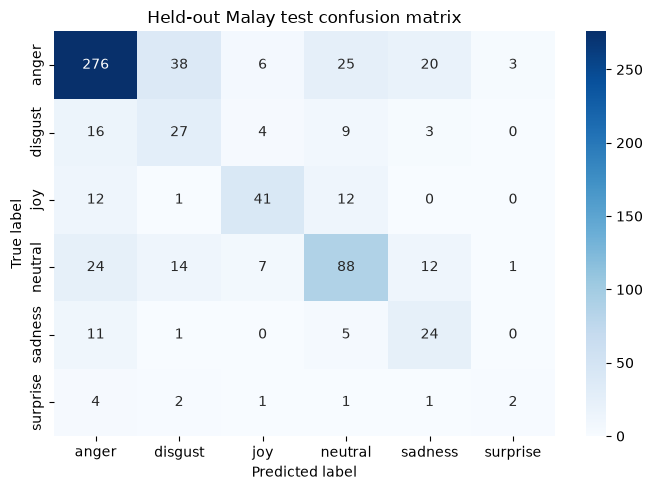

{
  "best_epoch": 8,
  "best_validation_macro_f1": 0.5368268643312344,
  "test_macro_f1": 0.5234942982670253,
  "test_accuracy": 0.6625180897250361,
  "per_dataset_macro_f1": {
    "mybully": 0.5230965426569787
  }
}


In [11]:
# Compact final results
summary_frame = pd.DataFrame({
    'metric': ['loss', 'accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1'],
    'value': [test_metrics[name] for name in ['loss', 'accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1']],
    'std': [test_metrics[f'{name}_std'] for name in ['loss', 'accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1']],
}).set_index('metric')
print('Held-out Malay test results (mean +/- std over 5 support draws)')
display(summary_frame.round(4))
print('Results by dataset')
display(per_dataset_frame[['rows', 'share', 'accuracy', 'macro_f1']].round(4))
print('Per-class results')
display(report.loc[CANONICAL_LABELS, ['precision', 'recall', 'f1-score', 'support']].round(4))

matrix = confusion_matrix(targets, predictions, labels=range(CONFIG['ways']))
fig, axis = plt.subplots(figsize=(7, 5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=CANONICAL_LABELS, yticklabels=CANONICAL_LABELS, ax=axis)
axis.set_xlabel('Predicted label')
axis.set_ylabel('True label')
axis.set_title('Held-out Malay test confusion matrix')
fig.tight_layout()
cm_path = FIGURES_DIR / 'malay_test_confusion_matrix.png'
fig.savefig(cm_path, dpi=180)
plt.show()

history_path = OUTPUTS_DIR / 'training_history.csv'
curves_path = FIGURES_DIR / 'training_validation_metrics.png'
summary = {
    'best_epoch': int(best_epoch),
    'best_validation_macro_f1': float(best_validation_raw['macro_f1']),
    'test_macro_f1': float(test_metrics['macro_f1']),
    'test_accuracy': float(test_metrics['accuracy']),
    'per_dataset_macro_f1': {name: float(values['macro_f1']) for name, values in per_dataset.items()},
}
print(json.dumps(summary, indent=2))
